# Ground Segment

Load the departure trajectory exported by `departure.ipynb`.
Time zero is the modeled periapsis burn, not surface liftoff.


**TODO:**
- Link budget
- Range and doppler plots
- Potential data uplink/downlink over the pass

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from cesium.communications import GroundStation, GroundStationNetwork
from cesium.constants import DAY_TO_SEC, HOUR_TO_SEC, M_TO_KM, RAD_TO_DEG
from cesium.math.rotations import wrap_to_pi
from cesium.math.time import jd_to_greg
from cesium.orbital.ephemeris import planet_elements_and_rv
from cesium.orbital.transformations import (
    ECEF_to_geodetic_LLA,
    calc_dcm_eci_wrt_hci,
    calc_dcm_gcrs_wrt_itrf,
    gcrs_to_itrf,
)
from cesium.plotting import plot_3d, plot_sky
from cesium.world.constants import R_EARTH
from mission_io import export_fig, load_mission
from tqdm import tqdm

## Load departure trajectory


In [3]:
MISSION_NAME = "birthday-christmas-earlier"
with load_mission("departure", MISSION_NAME) as trajectory:
    if (
        str(trajectory["frame"]) != "ECI"
        or str(trajectory["position_units"]) != "m"
        or str(trajectory["velocity_units"]) != "m/s"
    ):
        raise ValueError("Expected ECI states in meters and m/s")
    epoch_jd = float(trajectory["epoch_jd"])
    time_s = trajectory["time_s"].copy()
    rv_eci_m = trajectory["rv_eci_m"].copy()
    launch_site_lla_deg_m = trajectory["launch_site_lla_deg_m"].copy()

assert rv_eci_m.shape == (len(time_s), 6)
t_traj_jd = epoch_jd + time_s / DAY_TO_SEC
LAUNCH_LAT_DEG, LAUNCH_LON_DEG, LAUNCH_ALT_M = launch_site_lla_deg_m
print(f"Loaded {len(time_s)} departure states for {MISSION_NAME}")
print(f"Burn-reference epoch: {jd_to_greg(epoch_jd)}")
print(f"Duration: {time_s[-1] / HOUR_TO_SEC:.3f} hours")

Loaded 100000 departure states for birthday-christmas-earlier
Burn-reference epoch: (2035, 6, 14, 22, 4, 47.999993562698364)
Duration: 71.500 hours


## Earth-fixed trajectory


In [4]:
rv_departure_ecef = np.empty_like(rv_eci_m)
for i in tqdm(range(len(time_s)), desc="ECI → ECEF"):
    state = rv_eci_m[i]
    rv_departure_ecef[i] = np.concatenate(
        gcrs_to_itrf(state[:3], state[3:], t_traj_jd[i])
    )

ECI → ECEF: 100%|██████████| 100000/100000 [00:09<00:00, 10089.69it/s]


## Ground track


In [5]:
# Ground track
ground_track = np.empty_like(rv_departure_ecef[:, :2])
for i in tqdm(range(len(t_traj_jd)), desc="Ground track"):
    ground_track[i] = ECEF_to_geodetic_LLA(rv_departure_ecef[i, 0:3], deg=False)[0:2]
    ground_track[i, 1] = wrap_to_pi(ground_track[i, 1])
    ground_track[i] *= RAD_TO_DEG

Ground track: 100%|██████████| 100000/100000 [00:00<00:00, 185231.57it/s]


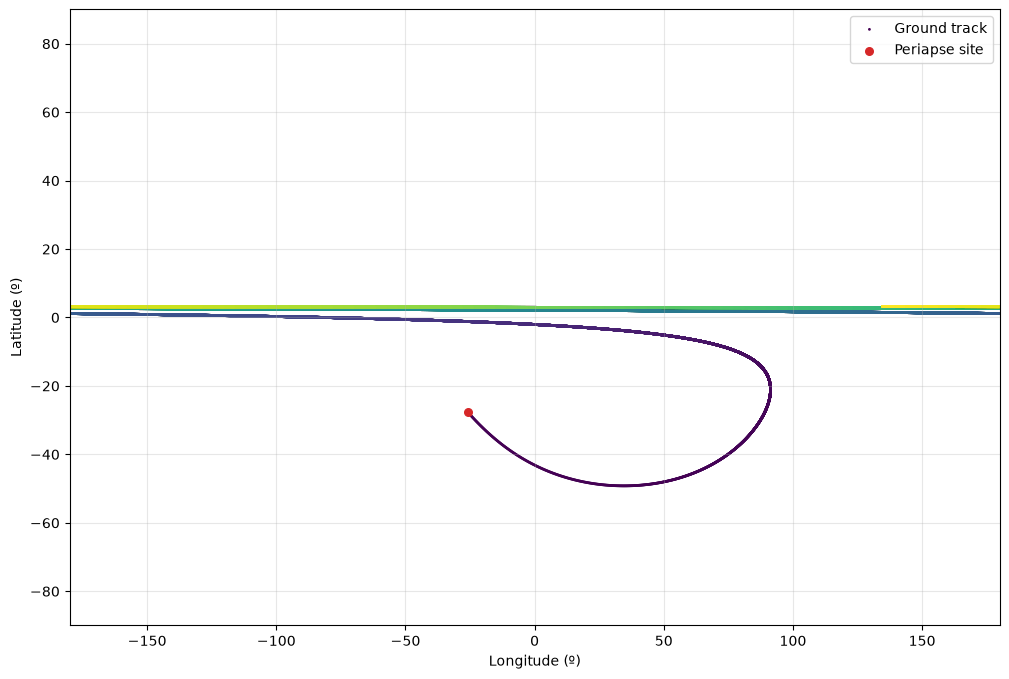

In [6]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(
    ground_track[:, 1],
    ground_track[:, 0],
    c=time_s,
    s=1,
    label="Ground track",
)

ax.set_xlim(-180, 180)
ax.set_xlabel("Longitude (º)")
ax.set_ylabel("Latitude (º)")
ax.scatter(
    ground_track[0, 1],
    ground_track[0, 0],
    label="Periapse site",
    marker="o",
    color="tab:red",
    s=30,
)
ax.set_ylim(-90, 90)
ax.legend()
ax.grid(True, alpha=0.3)
# ax.set_title(f"Ground track over {t_arr[-1] / MIN_TO_SEC} min")

In [ ]:
export_fig(fig, "ground_segment", "ground_track")

## ECEF visualization


In [12]:
# Initial-epoch reference vectors for this static view.
dcm_ecef_wrt_eci0 = calc_dcm_gcrs_wrt_itrf(epoch_jd).T
sun_direction_eci = calc_dcm_eci_wrt_hci() @ (-planet_elements_and_rv(3, epoch_jd)[1])
from cesium.orbital.transformations import geodetic_LLA_to_ECEF

r_cape_ecef_m = geodetic_LLA_to_ECEF(*launch_site_lla_deg_m)

# Translate by Earth's rv at each sample, then rotate HCI into ECI.

frames = [
    {
        "name": "ECEF",
        "location": [0, 0, 0],
        "dcm_body_wrt_hci": np.eye(3),
        "length": 10000,
    },
    # {"name": "ECEF", "location": [0, 0, 0],
    #         "dcm_body_wrt_hci": dcm_ecef_wrt_eci, "length": 10000},  # just for visualization
]

vectors = [
    {
        "direction": dcm_ecef_wrt_eci0 @ sun_direction_eci,
        "length": 20000,
        "name": "Initial Sun direction",
        "color": "goldenrod",
        "label": True,
    },
    {
        "direction": dcm_ecef_wrt_eci0 @ rv_eci_m[0, :3],
        "length": 10000,
        "name": "periapse",
        "color": "orange",
        "label": True,
    },
    # {"direction": n_vec, "length": 10000,
    #              "name": "Normal vec", "color": "black", "label": True},  # just for visualization
    # {"direction": right_vec, "length": 10000,
    #              "name": "right_vec", "color": "black", "label": True},  # just for visualization
]

points = [
    {"name": "Cape Canaveral", "location": r_cape_ecef_m * M_TO_KM, "color": "red"},
    {
        "name": "Periapsis (initial)",
        "location": (dcm_ecef_wrt_eci0 @ rv_eci_m[0, :3]) * M_TO_KM,
        "color": "orange",
    },
]

view_range = 1000000
fig_earth = plot_3d(
    [rv_departure_ecef[:, 0:3] * M_TO_KM],
    [time_s],
    labels=["Trajectory"],
    trace_colors=["black"],
    bodies={"name": "Earth", "radius": R_EARTH * M_TO_KM, "color": "royalblue"},
    frames=frames,
    vectors=vectors,
    points=points,
    title=f"Earth departure ECEF — {view_range} km view",
    units="km",
    azim=80,
    elev=30,
    show_end=False,
    show=False,
)
fig_earth.update_scenes(
    xaxis_range=[-view_range, view_range],  # km
    yaxis_range=[-view_range, view_range],  # km
    zaxis_range=[-view_range, view_range],  # km
)
fig_earth.show()

In [ ]:
export_fig(fig_earth, "ground_segment", "departure_ecef_3d")

## Cape Canaveral sky track


In [8]:
MIN_ELEVATION_DEG = 10.0
cape = GroundStation("Cape Canaveral", *launch_site_lla_deg_m)
az_el_rho, visible_mask = cape.sat_pass(rv_departure_ecef, MIN_ELEVATION_DEG)

Cape Canaveral az/el calculation: 100%|██████████| 100000/100000 [00:01<00:00, 99457.27it/s]


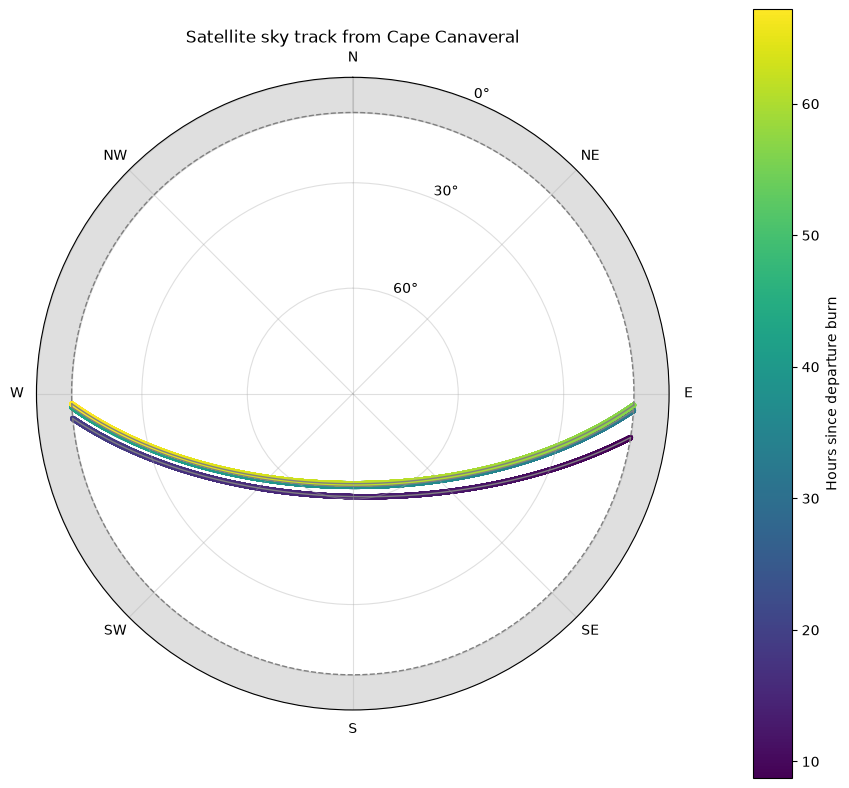

Visible interval 1 (sampled): (2035, 6, 15, 6, 49, 18.038713037967735) → (2035, 6, 15, 17, 7, 24.60154473781585)
  Peak elevation: 60.71 deg; duration: 10.302 hours
Visible interval 2 (sampled): (2035, 6, 16, 6, 42, 51.682812273502506) → (2035, 6, 16, 17, 15, 41.13653004169464)
  Peak elevation: 63.62 deg; duration: 10.547 hours
Visible interval 3 (sampled): (2035, 6, 17, 6, 38, 36.60228073596965) → (2035, 6, 17, 17, 15, 40.884509682655334)
  Peak elevation: 64.38 deg; duration: 10.618 hours


In [9]:
fig_sky, ax_sky = plot_sky(
    az_el_rho[:, 0],
    az_el_rho[:, 1],
    time_s / HOUR_TO_SEC,
    elevation_mask=MIN_ELEVATION_DEG,
    visible_mask=visible_mask,
    title="Satellite sky track from Cape Canaveral",
    time_label="Hours since departure burn",
)

if visible_mask.any():
    passes = np.split(
        np.flatnonzero(visible_mask),
        np.flatnonzero(np.diff(np.flatnonzero(visible_mask)) > 1) + 1,
    )
    for number, indices in enumerate(passes, 1):
        start_jd, end_jd = t_traj_jd[indices[0]], t_traj_jd[indices[-1]]
        print(
            f"Visible interval {number} (sampled): {jd_to_greg(start_jd)} → {jd_to_greg(end_jd)}"
        )
        print(
            f"  Peak elevation: {az_el_rho[indices, 1].max():.2f} deg; duration: {(end_jd - start_jd) * 24:.3f} hours"
        )
else:
    print(
        f"No satellite visibility above {MIN_ELEVATION_DEG:g} deg during this propagation."
    )

In [ ]:
export_fig(fig_sky, "ground_segment", "sky_track_cape")

## Ground-station network

Coordinates and thresholds are notebook configuration. `GroundStation` and
`GroundStationNetwork` are imported from `cesium.communications`; visibility
arrays are indexed `[station, time]`. Windows use sampled Julian-date bounds.


Vandenberg az/el calculation: 100%|██████████| 100000/100000 [00:00<00:00, 101623.53it/s]



Cape Canaveral: 3 visible intervals (sampled)
  JD 2464493.78423656 → 2464494.21347918
  JD 2464494.77976485 → 2464495.21922612
  JD 2464495.77681253 → 2464496.21922320

Svalbard: 2 visible intervals (sampled)
  JD 2464494.62040763 → 2464494.85317225
  JD 2464495.59549863 → 2464495.87107430

Punta Arenas: 3 visible intervals (sampled)
  JD 2464493.76493137 → 2464494.16447140
  JD 2464494.78062881 → 2464495.16232346
  JD 2464495.78154945 → 2464496.15972865

Goldstone: 3 visible intervals (sampled)
  JD 2464493.88767426 → 2464494.31346102
  JD 2464494.88192149 → 2464495.31882065
  JD 2464495.87858188 → 2464496.31887732

Madrid: 3 visible intervals (sampled)
  JD 2464493.57217736 → 2464494.00997027
  JD 2464494.55403113 → 2464495.02194373
  JD 2464495.54991692 → 2464496.02310270

Canberra: 4 visible intervals (sampled)
  JD 2464493.43945415 → 2464493.55275299
  JD 2464494.14981376 → 2464494.57005921
  JD 2464495.15279004 → 2464495.56898378
  JD 2464496.15183378 → 2464496.39916667

Vanden

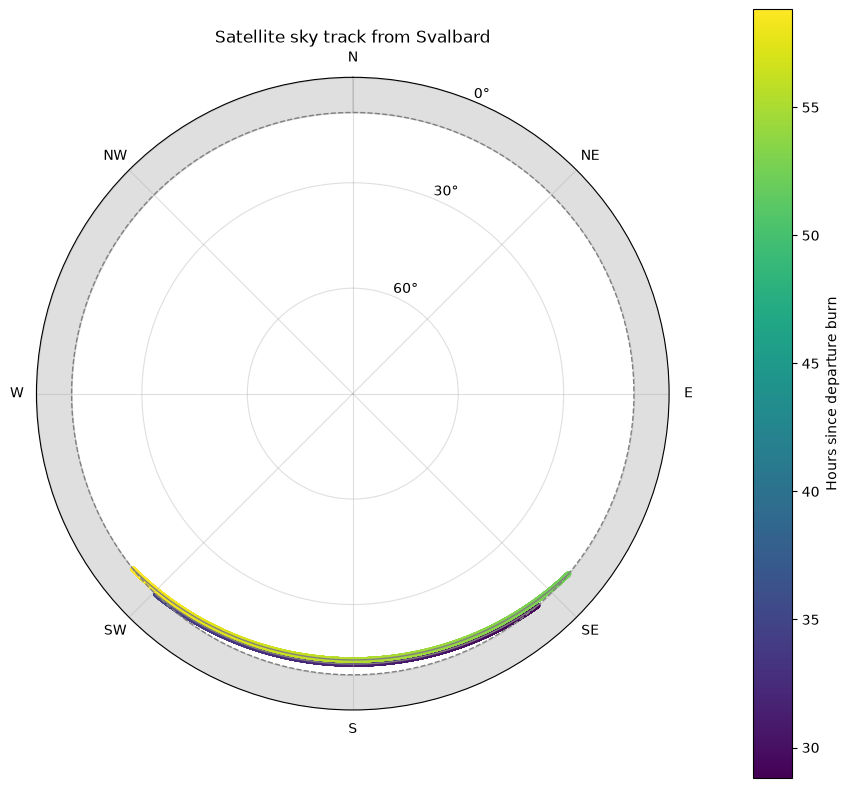

In [10]:
# Thresholds in degrees, in the same order as ground_stations.
elevation_masks_deg = [10, 10, 10, 10, 5, 10, 10]

ground_stations = [
    GroundStation("Cape Canaveral", *launch_site_lla_deg_m),
    GroundStation("Svalbard", 78.2289, 15.3967, 460),
    GroundStation("Punta Arenas", -52.9375, -70.8580, 15),
    GroundStation("Goldstone", 35.42590087, -116.88953821, 1001.390),
    GroundStation("Madrid", 40.43120975, -4.24800854, 864.816),
    GroundStation("Canberra", -35.40242423, 148.98126731, 688.867),
    GroundStation("Vandenberg", 34.7373, -120.5843, 0),
]

network = GroundStationNetwork(ground_stations).compute_visibility(
    rv_departure_ecef,
    t_traj_jd,
    elevation_masks_deg,
)

for station_name, windows in network.windows_jd.items():
    print(f"\n{station_name}: {len(windows)} visible intervals (sampled)")
    for start_jd, end_jd in windows:
        print(f"  JD {start_jd:.8f} → {end_jd:.8f}")

# GNSS-style availability: names and counts for each sample, not just any/all.
print(f"\nStations at first sample: {network.available_stations[0]}")
print(f"Maximum stations available together: {network.station_count.max()}")

station_name = "Svalbard"
station_i = list(network.station_names).index(station_name)
az_el_rho = network.az_el_rho[station_i]
visible_mask = network.visible_mask[station_i]
fig_station, ax_station = plot_sky(
    az_el_rho[:, 0],
    az_el_rho[:, 1],
    time_s / HOUR_TO_SEC,
    elevation_mask=network.elevation_masks_deg[station_i],
    visible_mask=visible_mask,
    title=f"Satellite sky track from {station_name}",
    time_label="Hours since departure burn",
)

In [ ]:
export_fig(fig_station, "ground_segment", "sky_track_station")

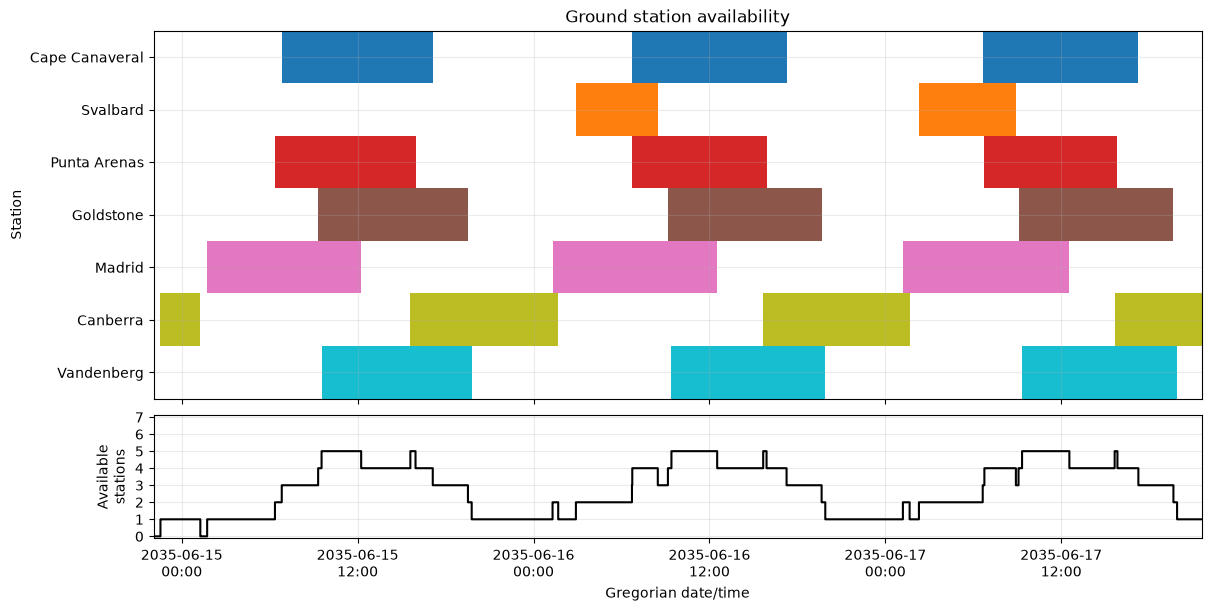

In [11]:
# time_axis: "gregorian", "jd", or "hours".
fig_network, axes_network = network.plot_visibility(time_axis="gregorian")

In [ ]:
export_fig(fig_network, "ground_segment", "network_visibility")

## Link budget — next steps

Use `network.az_el_rho[station_i, :, 2]` for slant range in meters. Add radio
frequency, transmitter power, spacecraft/ground antenna gains, pointing and
other losses, receiver noise, and a required link margin for each station.
Keep the resulting usable-link mask separate from geometric visibility.
